# Option Pricing

# 1. Objective

Compare two different option pricing methods

- 1. Analytic formula based on Black-Scholes equation

- 2. Monte Carlo simulation

# 2. Preliminary

## 2.1 Analytic formula

In this experiment, we focus on a European put option on an underlying asset paying a continuous dividend yield. Black-Scholes equation is given by

$$
\partial_t V+(r-q)S V_S+\frac{1}{2}\sigma^2 S^2 V_{SS}=rV.
$$

The analytic Black-Scholes formula for European put is 

$$
P_{BS}=Ke^{-rT}N(-d_2)-S_0e^{-qT} N(-d_1),
$$

where 

$$
d_1=\frac{1}{\sigma \sqrt{T}}\left[ \log\frac{S_0}{K}+(r-q+\frac{1}{2}\sigma^2)T\right],\quad d_2=d_1-\sigma \sqrt{T},
$$

and $N(x)$ is cumulative distribution function (CDF) for the standard norm distribution. The terminal payoff is given by

$$
V(S,T)=max(K-S,0). 
$$

## 2.2 Monte Carlo

In the risk-neutral measure, the stock price follows a geometric Brownian motion

$$
dS=(r-q)Sdt+\sigma SdW.
$$

Hence we get the stock price at time $T$

$$
S_T=S_0e^{(r-q-\frac{1}{2}\sigma^2)T+\sigma \sqrt{T}Z},\qquad Z\sim N(0,1),
$$

as well as the Monte Carlo price for European put option

$$
P_{MC}=\frac{1}{n}e^{-rT}\sum_{k=1}^n (K-S_T^{(k)})^+. 
$$

# 3. Experiment Design

Consider a $5$-month European put option on a dividend-paying stock when the stock price is $\$50$, the strike price is $\$50$, the risk-free interest rate is $10\%$ per annum, the continuous dividend yield is $0.3\%$ and the volatility is $40\%$ per annum. This means that $S_0=50,K=50,r=0.1,q=0.003,\sigma=0.4,T=5/12$.

# 4. Numerical Implementation

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT=Path.cwd().parent
SRC_DIR=PROJECT_ROOT/'src'

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0,str(SRC_DIR))

print(str(SRC_DIR) in sys.path)

True


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

The exact put price form BS formula is: 4.1001.

For N in [1000, 1500, 2000, 3000, 5000, 10000], 
the Monte Carlo simulation prices are: [4.1002 4.0942 4.1093 4.1052 4.1023 4.0967] respectively,
the corresponding errors are: [0.1751 0.1471 0.1342 0.1041 0.0811 0.0541].


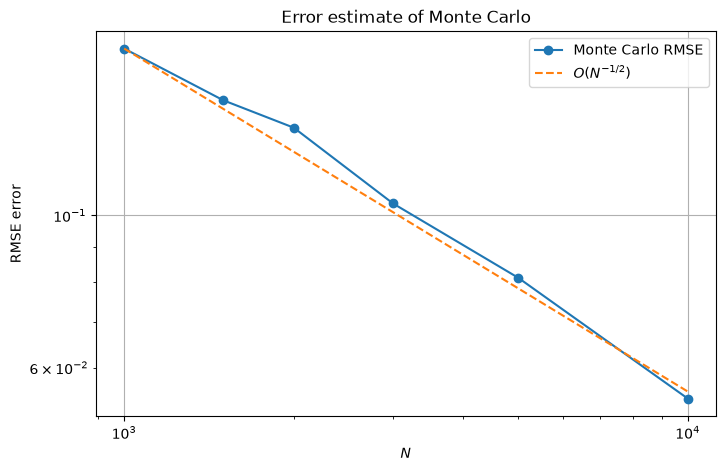

Estimated slope: -0.5144326023554683.


In [4]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import black_scholes as bs
import monte_carlo as mc


S0=50;K=50;T=5/12;r=0.1;q=0.003;sigma=0.4

# exact put option price form bs formula 
put_bs=bs.bs_calculator(S0,K,T,r,q,sigma,option_type='put')
print()
print(f'The exact put price form BS formula is: {put_bs:.4f}.')


# Monte Carlo
np.random.seed(2026) # Reproducibility

# Interval selection
N_interval=[1000,1500,2000,3000,5000,10000]

# Repetition
repeat=500

price_mc=[]
error_mc=[]

for N in N_interval:
    temp=[]
    
    for _ in range(repeat):
        temp.append(mc.mc_put(S0,K,T,r,q,sigma,N)[0])
    temp=np.array(temp)

    price_cur=np.mean(temp)
    price_mc.append(price_cur)
    error_mc.append(np.sqrt(
        np.mean((temp-put_bs)**2)
    ))
price_mc=np.array(price_mc)
error_mc=np.array(error_mc)
print()
print(f'For N in {N_interval}, \nthe Monte Carlo simulation prices are: {np.round(price_mc,4)} respectively,')
print(f'the corresponding errors are: {np.round(error_mc,4)}.')

# Plot
N_interval=np.array(N_interval)
reference_mc=(N_interval/N_interval[0])**(-0.5)*error_mc[0]

fig,ax=plt.subplots(figsize=(8,5))
plt.loglog(N_interval,error_mc,'o-',label='Monte Carlo RMSE')
plt.loglog(N_interval,reference_mc,'--',label=r'$O(N^{-1/2})$')
plt.xlabel(r'$N$')
plt.ylabel(r'RMSE error')
plt.title(r'Error estimate of Monte Carlo')
plt.legend()
plt.grid()
plt.show()

fig.savefig(
    PROJECT_ROOT/'figures'/'01_mc_convergence.png',
    dpi=300,
    bbox_inches='tight'
)


slope,intercept=np.polyfit(np.log(N_interval),np.log(error_mc),1)
print(f'Estimated slope: {slope}.')


# 5. Results and Analysis

## 5.1 Pricing Accuracy

The Monte Carlo estimates are close to the Black–Scholes price of 4.1001. The estimates fluctuate around the analytical value, with smaller variations for larger sample sizes.

## 5.2 Convergence Analysis

The RMSE decreases as the number of simulation paths increases. The estimated slope of the log-log regression is -0.5144, which is close to the theoretical rate of -0.5.

This confirms the expected $O(N^{-1/2})$ convergence of the Monte Carlo estimator.

## 5.3 Computational Efficiency

The convergence rate is relatively slow. Reducing the RMSE by half requires approximately four times as many simulation paths, illustrating the trade-off between computational cost and pricing accuracy.

# 6. Discussion and Conclusion

Monte Carlo simulation provides a reliable numerical approach to European put pricing. The experiment confirms its theoretical convergence rate of $O(N^{-1/2})$.

However, the slow convergence rate can lead to high computational costs when higher accuracy is required. In addition, the Black–Scholes framework relies on assumptions such as constant volatility and a constant risk-free rate, which may not fully capture real market behavior.

The results provide a numerical benchmark for the subsequent PDE pricing and option sensitivity analysis.